
# Task 2: Noise Filtering & Portfolio Validation

## 1. Project Objective

The objective of this task is to implement and evaluate statistical noise-filtering techniques for financial return covariance matrices.

We compare three approaches:

1. Raw covariance estimation (baseline).
2. Random Matrix Theory (RMT) using the Marchenko-Pastur distribution.
3. Ledoit-Wolf covariance shrinkage.

The filtered covariance matrices are used for minimum-variance portfolio construction and evaluated through rolling out-of-sample validation.

## 2. Research Questions

- Does RMT filtering improve portfolio risk estimation?
- Does Ledoit-Wolf shrinkage provide more stable covariance estimates?
- How do filtered portfolios compare against the raw covariance baseline?
- Which approach provides better out-of-sample variance forecasts and lower portfolio turnover?

## 3. Experimental Setup

| Parameter | Value |
|---|---|
| Asset class | US Stocks |
| Historical period | 2010–2017 |
| Selected stocks | 50 |
| Clean observations | 1,980 |
| Training window | 252 trading days |
| Testing window | 21 trading days |
| Rolling windows | 82 |
| Portfolio strategy | Minimum Variance |


In [1]:

# 2. Import Required Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from faultlines import get_log_return_matrix
from faultlines.filters import (
    rmt_filter,
    ledoit_wolf_filter,
    covariance_to_correlation
)

from faultlines.portfolio import (
    minimum_variance_weights,
    compare_portfolio_variance,
    rolling_portfolio_validation
)

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.8f}")

print("All libraries and project modules imported successfully!")


All libraries and project modules imported successfully!


In [2]:

# 3. Load and Prepare Dataset

START_DATE = "2010-01-01"
END_DATE = "2017-11-10"
N_STOCKS = 50

# Load returns while preserving missing observations
returns_df = get_log_return_matrix(
    start_date=START_DATE,
    end_date=END_DATE,
    asset_type="Stock",
    min_obs_pct=0.90,
    fill_missing=False
)

# Select 50 stocks with highest historical coverage
coverage = returns_df.notna().sum().sort_values(
    ascending=False,
    kind="mergesort"
)

selected_tickers = coverage.head(N_STOCKS).index

# Keep only complete observations
clean_returns = returns_df[selected_tickers].dropna()

print("Original dataset shape:", returns_df.shape)
print("Selected stocks:", len(selected_tickers))
print("Clean dataset shape:", clean_returns.shape)
print("Missing values:", clean_returns.isna().sum().sum())

print("\nDate range:")
print("Start:", clean_returns.index.min())
print("End:", clean_returns.index.max())

print("\nFirst five observations:")
display(clean_returns.head())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Original dataset shape: (1998, 3458)
Selected stocks: 50
Clean dataset shape: (1980, 50)
Missing values: 0

Date range:
Start: 2010-01-04 00:00:00
End: 2017-11-10 00:00:00

First five observations:


Ticker,a,aa,aaba,aapl,abc,abev,abt,abx,adbe,adi,adm,adp,adsk,aee,aem,aep,aes,aet,afl,ag,agn,aig,aiv,all,amat,amd,amgn,amzn,an,antm,apa,apc,apd,apri,arc,ash,asna,ati,atro,au,avp,avy,axp,azo,ba,bac,bax,bb,bbby,bbt
Date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2010-01-04,0.00736328,0.03221465,0.01889076,0.01536964,0.02132580,0.03636265,0.00870066,0.02536775,0.00839317,0.00289811,0.00513119,0.00025299,0.01018020,-0.00675792,0.04009028,0.00428862,0.02635006,0.04032723,0.02812477,0.03980625,0.01702276,-0.00299316,0.00252149,0.01217054,0.02546709,0.00206398,0.02014209,-0.00461963,0.00624677,0.02475327,0.02582607,0.03651354,0.02559106,-0.00703403,0.04736261,0.03814454,0.01674937,0.05457226,0.07759230,0.04809830,0.01947889,0.00980432,0.00988833,-0.00025308,0.03721340,0.04092060,-0.00671821,-0.02412644,0.01081063,0.01724707
2010-01-05,-0.01089786,-0.03162065,0.00757359,0.00174991,-0.00716908,-0.00761346,-0.00810606,0.01228626,0.01631270,-0.00167683,0.00532798,-0.00538982,-0.01530943,-0.00399952,0.01223578,-0.01151543,-0.01013163,-0.01442221,0.02861079,0.00970881,-0.00999165,-0.01898575,0.02487128,0.01633721,-0.00779225,0.00103040,-0.00871110,0.00588259,0.01544830,0.01079332,0.01157889,0.02773493,-0.00832190,-0.03593201,-0.00136147,-0.00592120,0.01940171,0.01096869,-0.02963705,0.01554012,0.00406614,0.00654784,-0.00221299,-0.00838792,0.03216366,0.03226623,-0.00687491,-0.00197373,-0.00925154,0.01424829
2010-01-06,-0.00354712,0.05068295,-0.00348838,-0.01604558,-0.00956945,0.00523540,0.00547197,0.02099384,-0.00212427,-0.00190891,-0.00249279,-0.00235526,0.00237061,-0.00692849,0.02410674,0.01016311,-0.01032178,-0.00405830,0.00874417,0.03325722,0.00328283,-0.00645834,0.01763428,0.00029935,-0.00195759,-0.01452308,-0.00757929,-0.01828177,0.03760784,0.01609366,0.01569260,0.00863387,-0.00831834,-0.00244200,0.00814116,0.01674900,0.03125254,0.02393980,-0.02943111,0.03126595,-0.00814889,-0.00219944,0.01602736,-0.00942466,0.02993174,0.01158565,0.00348032,-0.00609758,0.01436610,0.01513454
2010-01-07,-0.00129736,-0.02142399,-0.02775496,-0.00181532,-0.01612699,-0.01019765,0.00824243,-0.01415025,-0.01959531,-0.00786484,-0.01048542,-0.00044622,0.00550966,-0.00952598,-0.00927633,0.00860848,0.00077784,0.03136318,0.01063448,-0.02843794,-0.00804945,-0.01936784,0.03584510,0.00514965,-0.01067071,-0.01050430,-0.00913913,-0.01715962,0.01756143,0.03649187,-0.01548815,-0.00162688,-0.00569743,0.16007095,-0.00814116,-0.02204797,0.02123052,0.01420620,0.00915427,-0.01137314,-0.02552113,0.00937854,0.01170964,0.01318250,0.03968389,0.03234509,0.01602263,-0.00153022,0.06679716,0.03947648
2010-01-08,-0.00033663,0.02429869,0.00000000,0.00661557,0.01078017,0.01187369,0.00508357,0.00626978,-0.00543627,0.00572253,-0.01257688,-0.00137176,0.03015304,-0.00694499,0.02785225,0.01181824,0.02777483,-0.02213019,-0.01003671,0.02843794,-0.00737201,0.02618982,-0.02341626,0.00408588,0.03773422,-0.00423281,0.00881704,0.02671683,0.00048344,0.00438578,-0.00500073,0.00043827,0.00637249,0.19782574,0.00678889,-0.00197379,-0.01236307,0.02312010,0.00681112,0.01137314,0.00916861,0.01887508,-0.00068347,-0.01292487,-0.00965876,-0.00893650,0.00239773,0.00244723,0.00216448,-0.01119627



## 4. Covariance Estimation and Noise Filtering

Financial return matrices contain both meaningful correlations and estimation noise.

We evaluate three covariance estimation approaches:

### 4.1 Raw Covariance

The sample covariance matrix is calculated directly from historical stock returns. It serves as our baseline.

### 4.2 Random Matrix Theory (RMT)

The Marchenko-Pastur distribution provides theoretical bounds for eigenvalues expected under a random covariance model.

Eigenvalues within the estimated noise range are filtered, while eigenvalues outside that range are retained.

### 4.3 Ledoit-Wolf Shrinkage

Ledoit-Wolf shrinkage combines the sample covariance matrix with a structured target matrix to improve covariance estimation stability.

### 4.4 Evaluation

We compare the resulting covariance matrices using:
- Matrix symmetry.
- Minimum eigenvalue.
- Positive definiteness.
- Correlation matrix diagonal.


In [3]:

# 5. Covariance Estimation and Noise Filtering

# Calculate raw sample covariance
raw_cov = clean_returns.cov()

# Apply RMT filter
rmt_cov = rmt_filter(clean_returns)

# Apply Ledoit-Wolf shrinkage
lw_cov = ledoit_wolf_filter(clean_returns)

# Convert filtered covariance matrices to correlations
rmt_corr = covariance_to_correlation(rmt_cov)
lw_corr = covariance_to_correlation(lw_cov)

# Display matrix dimensions
print("Raw covariance:", raw_cov.shape)
print("RMT covariance:", rmt_cov.shape)
print("Ledoit-Wolf covariance:", lw_cov.shape)

print("\nMinimum eigenvalues:")
print("Raw:", np.linalg.eigvalsh(raw_cov).min())
print("RMT:", np.linalg.eigvalsh(rmt_cov).min())
print("Ledoit-Wolf:", np.linalg.eigvalsh(lw_cov).min())


Raw covariance: (50, 50)
RMT covariance: (50, 50)
Ledoit-Wolf covariance: (50, 50)

Minimum eigenvalues:
Raw: 2.5137138747888924e-05
RMT: 2.513637364876564e-05
Ledoit-Wolf: 3.114617412965561e-05


In [4]:

# 6. Covariance Matrix Validation

covariance_matrices = {
    "Raw": raw_cov,
    "RMT": rmt_cov,
    "Ledoit-Wolf": lw_cov
}

validation_results = []

for method, matrix in covariance_matrices.items():

    eigenvalues = np.linalg.eigvalsh(matrix)

    validation_results.append({
        "Method": method,
        "Shape": matrix.shape,
        "Symmetric": np.allclose(matrix, matrix.T),
        "Minimum Eigenvalue": eigenvalues.min(),
        "Positive Definite": eigenvalues.min() > 0
    })

validation_df = pd.DataFrame(validation_results)

display(validation_df)


,Method,Shape,Symmetric,Minimum Eigenvalue,Positive Definite
0,Raw,"(50, 50)",True,0.00002514,True
1,RMT,"(50, 50)",True,0.00002514,True
2,Ledoit-Wolf,"(50, 50)",True,0.00003115,True


In [5]:

# 7. Check the Effectiveness of RMT Filtering

raw_eigenvalues = np.linalg.eigvalsh(raw_cov)
rmt_eigenvalues = np.linalg.eigvalsh(rmt_cov)
lw_eigenvalues = np.linalg.eigvalsh(lw_cov)

print("Maximum absolute eigenvalue differences:")
print(
    "Raw vs RMT:",
    np.max(np.abs(raw_eigenvalues - rmt_eigenvalues))
)

print(
    "Raw vs Ledoit-Wolf:",
    np.max(np.abs(raw_eigenvalues - lw_eigenvalues))
)

print("\nCovariance matrix differences:")
print(
    "Raw vs RMT Frobenius norm:",
    np.linalg.norm(raw_cov - rmt_cov, ord="fro")
)

print(
    "Raw vs Ledoit-Wolf Frobenius norm:",
    np.linalg.norm(raw_cov - lw_cov, ord="fro")
)

print("\nNumber of eigenvalues changed by RMT:")
print(
    np.sum(
        ~np.isclose(raw_eigenvalues, rmt_eigenvalues)
    )
)


Maximum absolute eigenvalue differences:
Raw vs RMT: 2.5867549445730614e-05
Raw vs Ledoit-Wolf: 8.139876571437721e-05

Covariance matrix differences:
Raw vs RMT Frobenius norm: 0.0003411856412102956
Raw vs Ledoit-Wolf Frobenius norm: 9.9331393743985e-05

Number of eigenvalues changed by RMT:
49


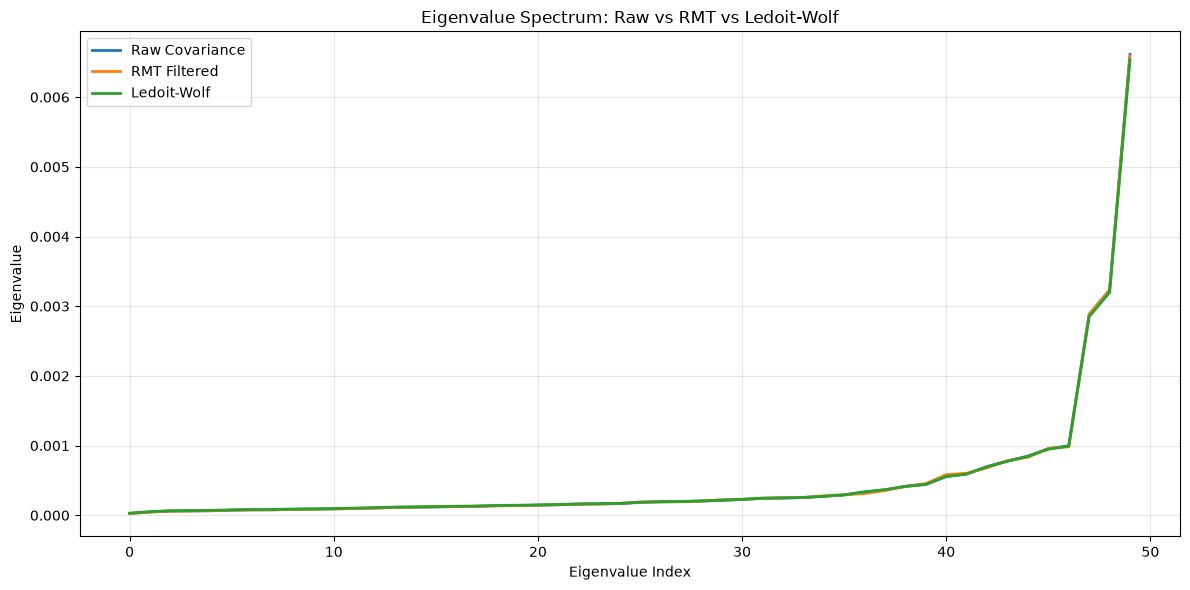

In [6]:

# 8. Eigenvalue Spectrum Comparison

raw_eigenvalues = np.sort(np.linalg.eigvalsh(raw_cov))
rmt_eigenvalues = np.sort(np.linalg.eigvalsh(rmt_cov))
lw_eigenvalues = np.sort(np.linalg.eigvalsh(lw_cov))

plt.figure(figsize=(12, 6))

plt.plot(
    raw_eigenvalues,
    label="Raw Covariance",
    linewidth=2
)

plt.plot(
    rmt_eigenvalues,
    label="RMT Filtered",
    linewidth=2
)

plt.plot(
    lw_eigenvalues,
    label="Ledoit-Wolf",
    linewidth=2
)

plt.title("Eigenvalue Spectrum: Raw vs RMT vs Ledoit-Wolf")
plt.xlabel("Eigenvalue Index")
plt.ylabel("Eigenvalue")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [7]:

# 9. Relative Covariance Matrix Differences

raw_norm = np.linalg.norm(raw_cov, ord="fro")

relative_rmt_change = (
    np.linalg.norm(raw_cov - rmt_cov, ord="fro")
    / raw_norm
)

relative_lw_change = (
    np.linalg.norm(raw_cov - lw_cov, ord="fro")
    / raw_norm
)

relative_comparison = pd.DataFrame({
    "Method": ["RMT", "Ledoit-Wolf"],
    "Relative Frobenius Change": [
        relative_rmt_change,
        relative_lw_change
    ]
})

display(relative_comparison)


,Method,Relative Frobenius Change
0,RMT,0.04125199
1,Ledoit-Wolf,0.01200994


In [8]:

# 10. Marchenko-Pastur Theoretical Bounds

n_obs, n_assets = clean_returns.shape

q = n_assets / n_obs

lambda_min = (1 - np.sqrt(q)) ** 2
lambda_max = (1 + np.sqrt(q)) ** 2

# Eigenvalues of the sample correlation matrix
raw_correlation = clean_returns.corr()

correlation_eigenvalues = np.linalg.eigvalsh(
    raw_correlation
)

# Classify eigenvalues
below_noise = np.sum(
    correlation_eigenvalues < lambda_min
)

inside_noise = np.sum(
    (correlation_eigenvalues >= lambda_min) &
    (correlation_eigenvalues <= lambda_max)
)

above_noise = np.sum(
    correlation_eigenvalues > lambda_max
)

print("Number of observations:", n_obs)
print("Number of assets:", n_assets)
print("Q ratio:", q)

print("\nMarchenko-Pastur bounds:")
print("Lower bound:", lambda_min)
print("Upper bound:", lambda_max)

print("\nEigenvalue distribution:")
print("Below noise range:", below_noise)
print("Inside noise range:", inside_noise)
print("Above noise range:", above_noise)


Number of observations: 1980
Number of assets: 50
Q ratio: 0.025252525252525252

Marchenko-Pastur bounds:
Lower bound: 0.7074316621706612
Upper bound: 1.3430733883343893

Eigenvalue distribution:
Below noise range: 33
Inside noise range: 13
Above noise range: 4


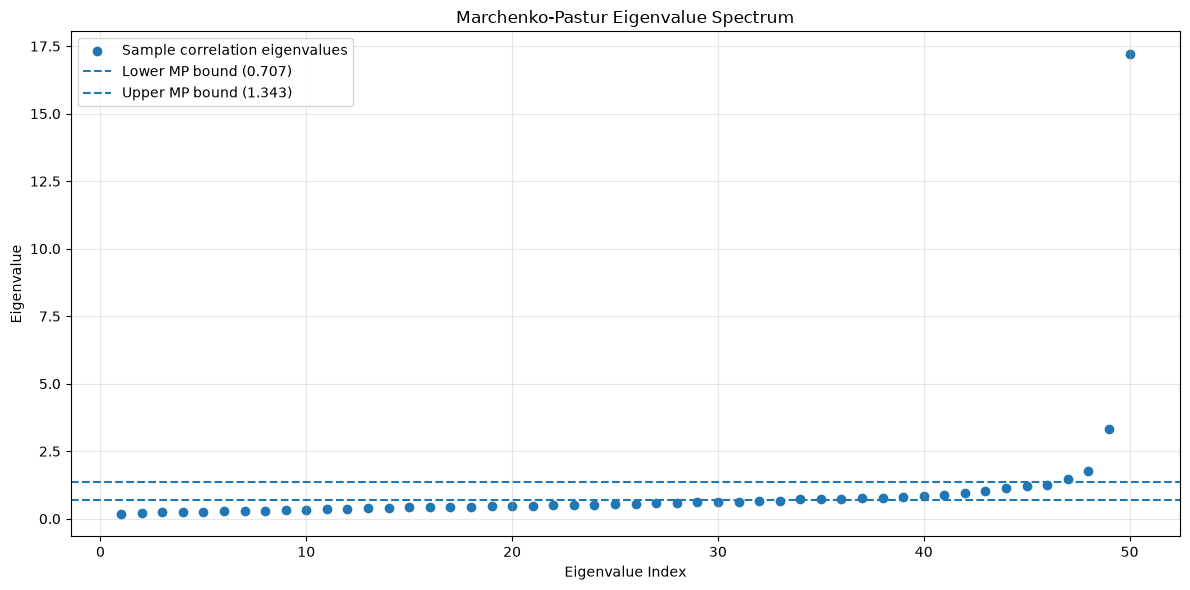

In [9]:

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 6))

sorted_eigenvalues = np.sort(correlation_eigenvalues)

plt.scatter(
    range(1, len(sorted_eigenvalues) + 1),
    sorted_eigenvalues,
    label="Sample correlation eigenvalues"
)

plt.axhline(
    lambda_min,
    linestyle="--",
    label=f"Lower MP bound ({lambda_min:.3f})"
)

plt.axhline(
    lambda_max,
    linestyle="--",
    label=f"Upper MP bound ({lambda_max:.3f})"
)

plt.xlabel("Eigenvalue Index")
plt.ylabel("Eigenvalue")
plt.title("Marchenko-Pastur Eigenvalue Spectrum")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [10]:

# 11. Inspect RMT Filter Implementation

import inspect
from faultlines.filters import rmt_filter

print(inspect.getsource(rmt_filter))


def rmt_filter(returns):
    """
    Marchenko-Pastur RMT denoising.

    1. Calculate the sample correlation matrix.
    2. Calculate its eigenvalues and eigenvectors.
    3. Estimate the Marchenko-Pastur upper noise boundary.
    4. Replace noise eigenvalues with their average.
    5. Reconstruct and rescale the covariance matrix.

    Returns a denoised covariance matrix.
    """

    X, columns = _validate_returns(returns)

    n, p = X.shape

    # Calculate sample standard deviations
    std = np.std(X, axis=0, ddof=1)

    # Calculate correlation matrix
    corr = np.corrcoef(X, rowvar=False)

    # Eigenvalue decomposition
    eigenvalues, eigenvectors = np.linalg.eigh(corr)

    # Marchenko-Pastur theoretical noise boundaries
    q = p / n
    lambda_min = (1 - np.sqrt(q)) ** 2
    lambda_max = (1 + np.sqrt(q)) ** 2

    # Identify eigenvalues inside the noise spectrum
    noise_mask = ((eigenvalues >= lambda_min) & (eigenvalues <= lambda_max))

    # Start with the original e

In [11]:
# Display remaining RMT implementation

source = inspect.getsource(rmt_filter)
lines = source.splitlines()

print("\n".join(lines[25:]))


    # Marchenko-Pastur theoretical noise boundaries
    q = p / n
    lambda_min = (1 - np.sqrt(q)) ** 2
    lambda_max = (1 + np.sqrt(q)) ** 2

    # Identify eigenvalues inside the noise spectrum
    noise_mask = ((eigenvalues >= lambda_min) & (eigenvalues <= lambda_max))

    # Start with the original eigenvalues
    filtered_eigenvalues = eigenvalues.copy()

    # Remove tiny negative numerical eigenvalues
    filtered_eigenvalues = np.maximum(filtered_eigenvalues, 0)

    if np.any(noise_mask):
        noise_average = np.mean(filtered_eigenvalues[noise_mask])
        filtered_eigenvalues[noise_mask] = noise_average

    # Reconstruct filtered correlation matrix
    filtered_corr = (
        eigenvectors
        @ np.diag(filtered_eigenvalues)
        @ eigenvectors.T
    )

    # Normalize diagonal to 1
    diagonal = np.sqrt(np.maximum(np.diag(filtered_corr), 1e-12))
    filtered_corr = filtered_corr / np.outer(diagonal, diagonal)

    # Convert correlation back to covariance
  

In [12]:
source = inspect.getsource(rmt_filter)
lines = source.splitlines()

for i, line in enumerate(lines):
    if "filtered_corr" in line or "filtered_cov" in line:
        print(f"{i}: {line}")
        print("\n".join(lines[i:i+18]))
        print("-" * 50)

45:     filtered_corr = (
    filtered_corr = (
        eigenvectors
        @ np.diag(filtered_eigenvalues)
        @ eigenvectors.T
    )

    # Normalize diagonal to 1
    diagonal = np.sqrt(np.maximum(np.diag(filtered_corr), 1e-12))
    filtered_corr = filtered_corr / np.outer(diagonal, diagonal)

    # Convert correlation back to covariance
    filtered_cov = np.outer(std, std) * filtered_corr
    filtered_cov = (filtered_cov + filtered_cov.T) / 2

    return pd.DataFrame(
        filtered_cov,
        index=columns,
        columns=columns
--------------------------------------------------
52:     diagonal = np.sqrt(np.maximum(np.diag(filtered_corr), 1e-12))
    diagonal = np.sqrt(np.maximum(np.diag(filtered_corr), 1e-12))
    filtered_corr = filtered_corr / np.outer(diagonal, diagonal)

    # Convert correlation back to covariance
    filtered_cov = np.outer(std, std) * filtered_corr
    filtered_cov = (filtered_cov + filtered_cov.T) / 2

    return pd.DataFrame(
        filtere

In [13]:

# 12. Final RMT Reconstruction Validation

rmt_corr_check = covariance_to_correlation(rmt_cov)

print("RMT covariance symmetric:",
      np.allclose(rmt_cov, rmt_cov.T))

print("RMT correlation symmetric:",
      np.allclose(rmt_corr_check, rmt_corr_check.T))

print("Correlation diagonal close to 1:",
      np.allclose(np.diag(rmt_corr_check), 1.0))

print("RMT minimum eigenvalue:",
      np.linalg.eigvalsh(rmt_cov).min())

print("RMT positive definite:",
      np.linalg.eigvalsh(rmt_cov).min() > 0)

print("RMT covariance shape:", rmt_cov.shape)


RMT covariance symmetric: True
RMT correlation symmetric: True
Correlation diagonal close to 1: True
RMT minimum eigenvalue: 2.513637364876564e-05
RMT positive definite: True
RMT covariance shape: (50, 50)


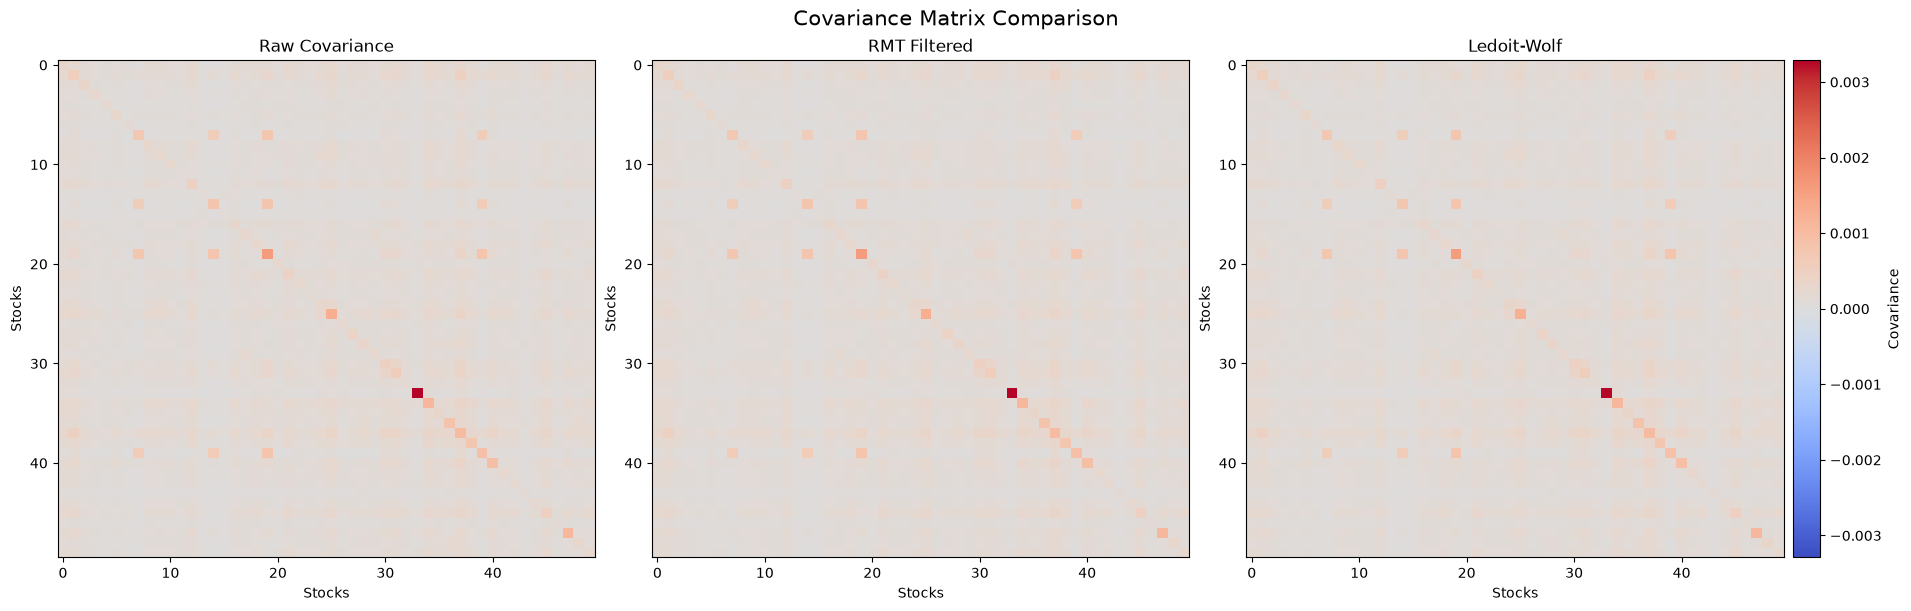

In [15]:

# 13. Improved Covariance Matrix Heatmaps

fig = plt.figure(figsize=(19, 6), constrained_layout=True)

gs = fig.add_gridspec(
    1, 4,
    width_ratios=[1, 1, 1, 0.05]
)

axes = [fig.add_subplot(gs[0, i]) for i in range(3)]
cax = fig.add_subplot(gs[0, 3])

matrices = [
    ("Raw Covariance", raw_cov),
    ("RMT Filtered", rmt_cov),
    ("Ledoit-Wolf", lw_cov)
]

vmax = max(
    np.abs(matrix.to_numpy()).max()
    for _, matrix in matrices
)

for ax, (title, matrix) in zip(axes, matrices):

    im = ax.imshow(
        matrix,
        cmap="coolwarm",
        vmin=-vmax,
        vmax=vmax,
        aspect="auto"
    )

    ax.set_title(title)
    ax.set_xlabel("Stocks")
    ax.set_ylabel("Stocks")

fig.colorbar(im, cax=cax, label="Covariance")

fig.suptitle("Covariance Matrix Comparison", fontsize=15)

plt.show()


In [17]:
%whos

Variable                       Type         Data/Info
-----------------------------------------------------
END_DATE                       str          2017-11-10
N_STOCKS                       int          50
Path                           type         <class 'pathlib.Path'>
START_DATE                     str          2010-01-01
above_noise                    int64        4
ax                             Axes         Axes(0.652933,0.0794504;0.28278x0.829151)
axes                           list         n=3
below_noise                    int64        33
cax                            Axes         Axes(0.940713,0.0794504;0.014139x0.829151)
clean_returns                  DataFrame    Shape: (1980, 50)
compare_portfolio_variance     function     <function compare_portfol<...>ce at 0x00000277328C4F40>
correlation_eigenvalues        ndarray      50: 50 elems, type `float64`, 400 bytes
covariance_matrices            dict         n=3
covariance_to_correlation      function     <function covari

In [18]:
print("Validation DataFrame:")
print(validation_df.to_string())

print("\nColumn names:")
print(validation_df.columns.tolist())

Validation DataFrame:
        Method     Shape  Symmetric  Minimum Eigenvalue  Positive Definite
0          Raw  (50, 50)       True          0.00002514               True
1          RMT  (50, 50)       True          0.00002514               True
2  Ledoit-Wolf  (50, 50)       True          0.00003115               True

Column names:
['Method', 'Shape', 'Symmetric', 'Minimum Eigenvalue', 'Positive Definite']


In [20]:

from pathlib import Path
import pandas as pd

results_path = Path("../results")

print("Results folder exists:", results_path.exists())

# Load saved portfolio results
summary = pd.read_csv(
    results_path / "rolling_summary.csv",
    index_col=0
)

print("\nPortfolio Summary:")
print(summary)

print("\nColumns:")
print(summary.columns.tolist())


Results folder exists: True

Portfolio Summary:
             OOS_Daily_Variance  OOS_Annualized_Volatility
Method                                                    
Raw                  0.00005368                 0.11631027
RMT                  0.00005347                 0.11608334
Ledoit-Wolf          0.00005343                 0.11603126

Columns:
['OOS_Daily_Variance', 'OOS_Annualized_Volatility']


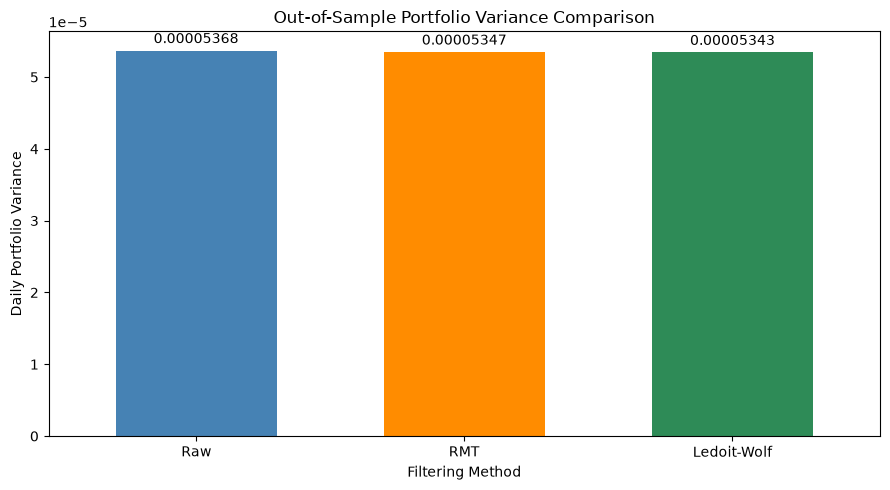

In [21]:

# 14. Out-of-Sample Portfolio Variance Comparison

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

ax = summary["OOS_Daily_Variance"].plot(
    kind="bar",
    color=["steelblue", "darkorange", "seagreen"],
    width=0.6
)

plt.title("Out-of-Sample Portfolio Variance Comparison")
plt.xlabel("Filtering Method")
plt.ylabel("Daily Portfolio Variance")
plt.xticks(rotation=0)

# Display values above bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.8f", padding=3)

plt.tight_layout()
plt.show()


In [22]:

# 15. Inspect Rolling Window Results

rolling_results = pd.read_csv(
    results_path / "rolling_window_results.csv"
)

print("Shape:", rolling_results.shape)

print("\nColumns:")
print(rolling_results.columns.tolist())

print("\nFirst 10 rows:")
display(rolling_results.head(10))

print("\nMethods:")
print(rolling_results["Method"].unique())


Shape: (246, 11)

Columns:
['Method', 'Estimated_Daily_Variance', 'Realized_Daily_Variance', 'Annualized_Realized_Volatility', 'Variance_Forecast_Absolute_Error', 'Variance_Forecast_Squared_Error', 'Turnover', 'Train_Start', 'Train_End', 'Test_Start', 'Test_End']

First 10 rows:


,Method,Estimated_Daily_Variance,Realized_Daily_Variance,Annualized_Realized_Volatility,Variance_Forecast_Absolute_Error,Variance_Forecast_Squared_Error,Turnover,Train_Start,Train_End,Test_Start,Test_End
0,Raw,0.00005556,0.00003544,0.09449922,0.00002012,0.00000000,NaN,2010-01-04,2010-12-31,2011-01-03,2011-02-01
1,RMT,0.00005613,0.00003392,0.09246072,0.00002221,0.00000000,NaN,2010-01-04,2010-12-31,2011-01-03,2011-02-01
2,Ledoit-Wolf,0.00005924,0.00003395,0.09249570,0.00002529,0.00000000,NaN,2010-01-04,2010-12-31,2011-01-03,2011-02-01
3,Raw,0.00005391,0.00003465,0.09344107,0.00001926,0.00000000,0.05238317,2010-02-03,2011-02-01,2011-02-02,2011-03-03
4,RMT,0.00005530,0.00003428,0.09294668,0.00002102,0.00000000,0.07818165,2010-02-03,2011-02-01,2011-02-02,2011-03-03
5,Ledoit-Wolf,0.00005660,0.00003378,0.09225914,0.00002282,0.00000000,0.05197238,2010-02-03,2011-02-01,2011-02-02,2011-03-03
6,Raw,0.00005227,0.00005814,0.12104258,0.00000587,0.00000000,0.10372934,2010-03-05,2011-03-03,2011-03-04,2011-04-01
7,RMT,0.00005308,0.00005996,0.12292637,0.00000688,0.00000000,0.10807123,2010-03-05,2011-03-03,2011-03-04,2011-04-01
8,Ledoit-Wolf,0.00005459,0.00006127,0.12425954,0.00000669,0.00000000,0.07426363,2010-03-05,2011-03-03,2011-03-04,2011-04-01
9,Raw,0.00005476,0.00003061,0.08782712,0.00002415,0.00000000,0.02731752,2010-04-06,2011-04-01,2011-04-04,2011-05-03



Methods:
<StringArray>
['Raw', 'RMT', 'Ledoit-Wolf']
Length: 3, dtype: str


In [23]:

# 16. Rolling Window Performance Summary

print("Number of windows per method:")
print(rolling_results["Method"].value_counts())

print("\nMissing values:")
print(rolling_results.isna().sum())

rolling_performance = (
    rolling_results
    .groupby("Method")
    .agg(
        Average_Estimated_Variance=(
            "Estimated_Daily_Variance", "mean"
        ),
        Average_Realized_Variance=(
            "Realized_Daily_Variance", "mean"
        ),
        Average_Annualized_Volatility=(
            "Annualized_Realized_Volatility", "mean"
        ),
        Average_Forecast_Error=(
            "Variance_Forecast_Absolute_Error", "mean"
        ),
        Average_Turnover=("Turnover", "mean")
    )
)

print("\nROLLING PERFORMANCE SUMMARY:")
display(rolling_performance.round(8))


Number of windows per method:
Method
Raw            82
RMT            82
Ledoit-Wolf    82
Name: count, dtype: int64

Missing values:
Method                              0
Estimated_Daily_Variance            0
Realized_Daily_Variance             0
Annualized_Realized_Volatility      0
Variance_Forecast_Absolute_Error    0
Variance_Forecast_Squared_Error     0
Turnover                            3
Train_Start                         0
Train_End                           0
Test_Start                          0
Test_End                            0
dtype: int64

ROLLING PERFORMANCE SUMMARY:


,Average_Estimated_Variance,Average_Realized_Variance,Average_Annualized_Volatility,Average_Forecast_Error,Average_Turnover
Method,,,,,
Ledoit-Wolf,0.00004707,0.00005407,0.10801623,0.00003049,0.10488310
RMT,0.00004552,0.00005401,0.10837533,0.00002930,0.12303029
Raw,0.00004614,0.00005417,0.10849062,0.00002929,0.12287028


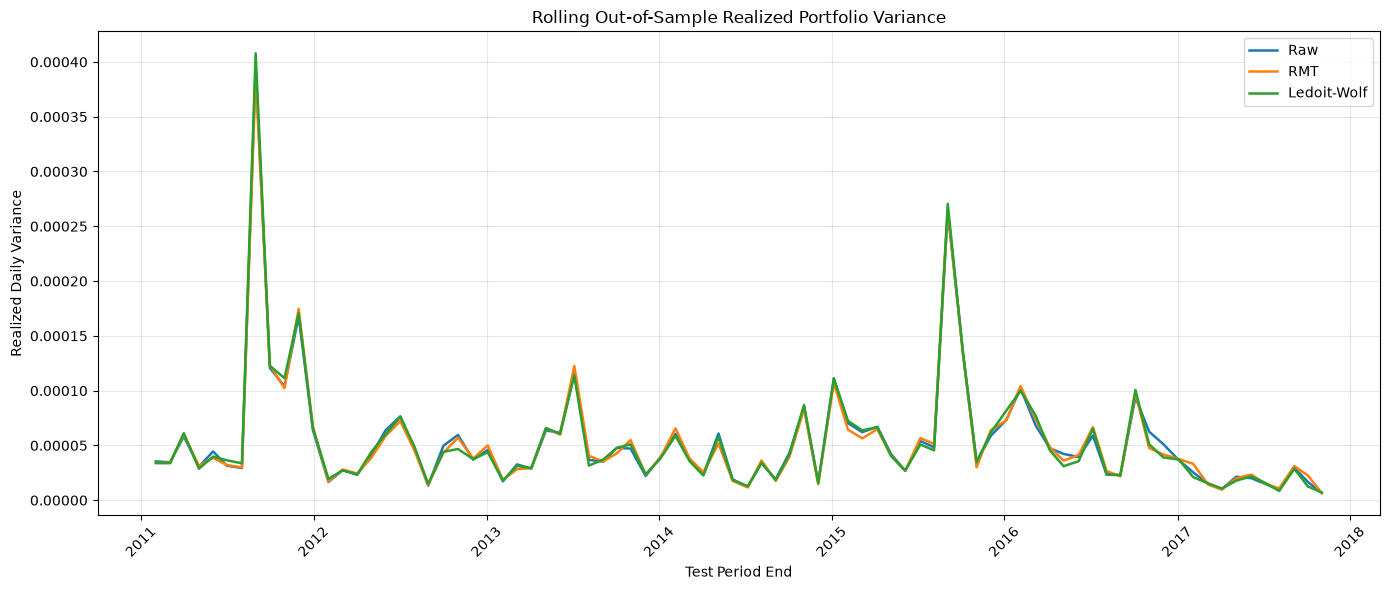

In [24]:

# 17. Rolling Realized Variance Comparison

rolling_results["Test_End"] = pd.to_datetime(
    rolling_results["Test_End"]
)

plt.figure(figsize=(14, 6))

for method in ["Raw", "RMT", "Ledoit-Wolf"]:

    subset = rolling_results[
        rolling_results["Method"] == method
    ].sort_values("Test_End")

    plt.plot(
        subset["Test_End"],
        subset["Realized_Daily_Variance"],
        label=method,
        linewidth=1.8
    )

plt.title("Rolling Out-of-Sample Realized Portfolio Variance")
plt.xlabel("Test Period End")
plt.ylabel("Realized Daily Variance")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


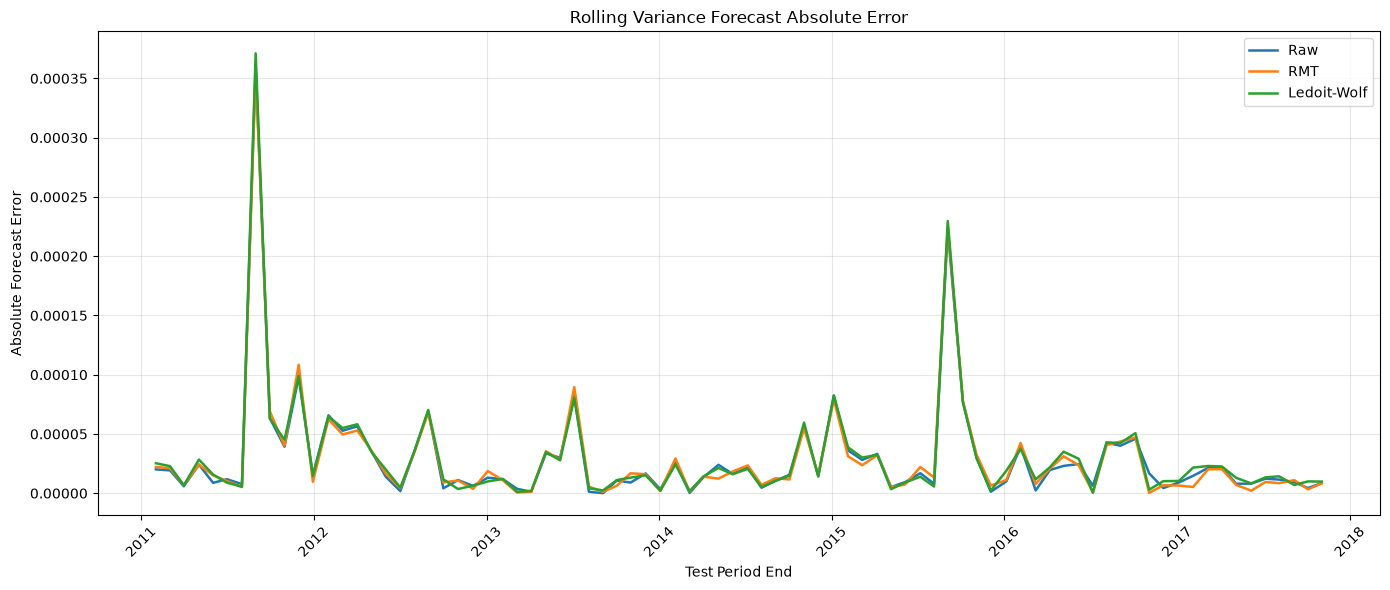

In [25]:

# 18. Rolling Variance Forecast Accuracy

plt.figure(figsize=(14, 6))

for method in ["Raw", "RMT", "Ledoit-Wolf"]:

    subset = rolling_results[
        rolling_results["Method"] == method
    ].sort_values("Test_End")

    plt.plot(
        subset["Test_End"],
        subset["Variance_Forecast_Absolute_Error"],
        label=method,
        linewidth=1.8
    )

plt.title("Rolling Variance Forecast Absolute Error")
plt.xlabel("Test Period End")
plt.ylabel("Absolute Forecast Error")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


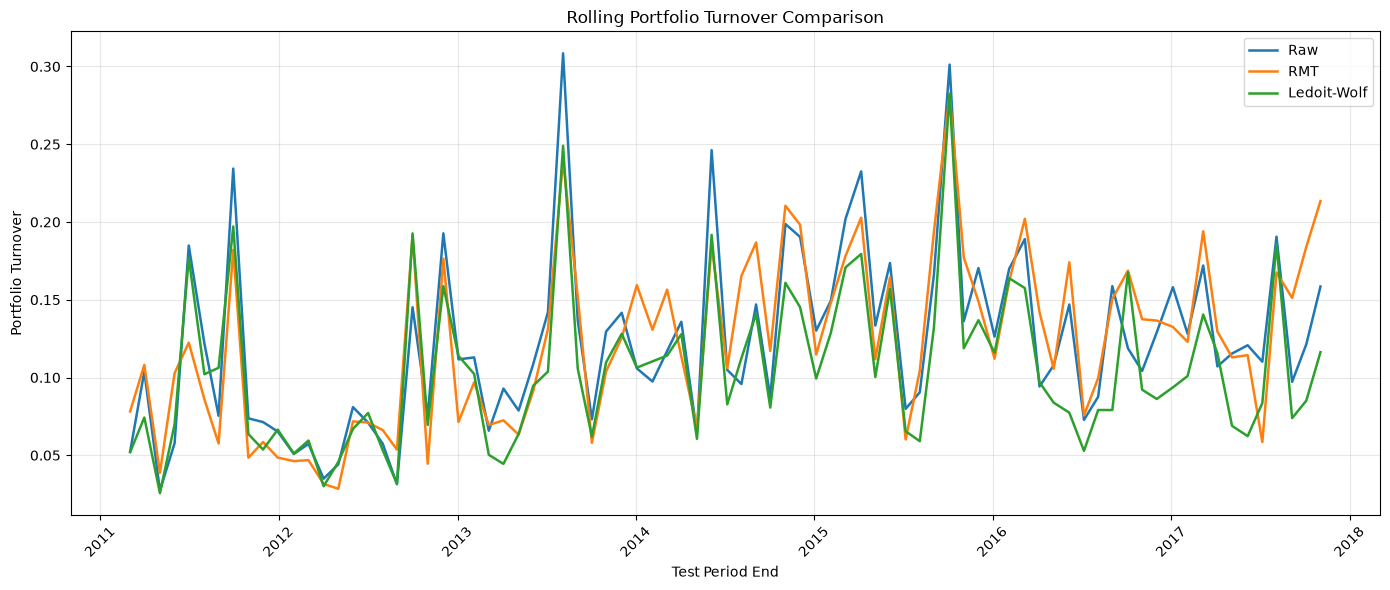

In [26]:

# 19. Rolling Portfolio Turnover Comparison

plt.figure(figsize=(14, 6))

for method in ["Raw", "RMT", "Ledoit-Wolf"]:

    subset = rolling_results[
        rolling_results["Method"] == method
    ].sort_values("Test_End")

    plt.plot(
        subset["Test_End"],
        subset["Turnover"],
        label=method,
        linewidth=1.8
    )

plt.title("Rolling Portfolio Turnover Comparison")
plt.xlabel("Test Period End")
plt.ylabel("Portfolio Turnover")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
